# Project 08 · Mortgage Knowledge Assistant: Retrieval, Reranking & Grounding

**Track:** LLM / RAG  
**Research / product question:** Can an assistant retrieve the right policy and justify every answer with current evidence?

**Learning outcome:** Implement BM25 and hybrid retrieval, tune retrieval parameters, evaluate citation coverage and define a pluggable generation interface.

**Workflow:** Data-generating process → raw-data audit → leakage-safe features → from-scratch baseline → model selection / hyperparameter tuning → held-out evaluation → failure analysis.

> **Synthetic-data disclosure:** All records and outcomes are created in this notebook; they do not describe real customers or credit decisions. Ground truth is constructed for teaching. Numerical results are illustrative of this simulator, not estimates of real-world business impact.

**Reproducibility:** Random seeds are fixed. Run cells top-to-bottom. Install packages from the project-level `requirements.txt`. CPU execution is supported; deep-learning examples deliberately use small models.

> **Portfolio standard:** fully reproducible, synthetic educational data · explicit evaluation protocol · plots and failure analysis · no claims of production accuracy.

A fully runnable *offline* retrieval pipeline compares BM25, SVD-based low-rank semantic retrieval and reciprocal-rank fusion. The answerer quotes a supporting policy and returns its policy ID.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'grid.alpha': 0.2})

## 1. Simulate a versioned mortgage servicing knowledge base

A synthetic handbook provides explicit effective dates, policy rules and references. These rules are fictional—**not legal, financial or servicing advice**. Several near-duplicate policies make retrieval more realistic.

In [2]:
# Fictional mortgage-servicing policies must not be treated as regulatory guidance.
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity
policies=[
('P01','Payment grace period','A regular monthly payment is considered late for fee purposes after a fictional 14 day grace period.','grace'),
('P02','Late fees','A fictional late fee can be 3 percent of overdue principal and interest after the grace period, subject to account restrictions.','fee'),
('P03','Escrow shortage','A borrower with an escrow shortage can request a repayment plan under the fictional servicing policy.','escrow'),
('P04','Extra principal','A borrower may designate an extra payment for principal reduction subject to loan terms.','prepay'),
('P05','Refinance application','Refinancing replaces a loan and involves a new underwriting decision and closing costs.','refinance'),
('P06','Assistance review','Borrowers with documented hardship may request assistance review; approval is not guaranteed.','assistance'),
('P07','Loan modification','A modification request may change monthly payments only if the borrower qualifies after review.','modification'),
('P08','Insurance renewal','Insurance renewal documents may affect escrow estimates when premiums change.','insurance'),
('P09','Credit reporting','Servicers may report payment history according to applicable program and reporting rules.','credit'),
('P10','Home equity','Home equity is the difference between a property value and secured loan balances.','equity'),
('P11','Payment due date','Monthly payments are ordinarily scheduled for the date specified in the loan contract.','due'),
('P12','Customer complaints','The fictional servicer logs complaints with a case number and escalation contact.','complaint')]
docs=pd.DataFrame(policies,columns=['id','title','body','intent']);docs['text']=docs.title+'. '+docs.body
questions={
'grace':['How many days is the grace period?','When is a payment late for fees?'],
'fee':['How are overdue late fees determined?','What is the missed payment fee?'],
'escrow':['Can I spread out an escrow shortage?','How do I handle escrow deficit?'],
'prepay':['Can I make extra principal payments?','Does paying extra reduce principal?'],
'refinance':['Do I have to apply for a refinance?','Does refinancing incur closing costs?'],
'assistance':['Can I ask for hardship assistance?','Is hardship help automatically approved?'],
'modification':['How do loan modifications work?','Can payments change under a modification?'],
'insurance':['Why does my insurance increase escrow?','What affects insurance renewal escrow?'],
'credit':['Will late payments appear on my credit record?','How is repayment reported to credit bureaus?'],
'equity':['What does home equity mean?','Is my property value minus debt my equity?'],
'due':['Where can I find my payment due date?','When is my monthly mortgage bill due?'],
'complaint':['How to submit a complaint?','Where can I escalate a servicing issue?']}
qdf=pd.DataFrame([(q,t) for t,qs in questions.items() for q in qs],columns=['query','intent']);qid={t:i for i,t in enumerate(docs.intent)};qdf['target_id']=qdf.intent.map(qid)
print('Documents:',len(docs),'Evaluation questions:',len(qdf));print(docs[['id','title','body']].head().to_string(index=False))

Documents: 12 Evaluation questions: 24
 id                 title                                                                                                                             body
P01  Payment grace period                             A regular monthly payment is considered late for fee purposes after a fictional 14 day grace period.
P02             Late fees A fictional late fee can be 3 percent of overdue principal and interest after the grace period, subject to account restrictions.
P03       Escrow shortage                            A borrower with an escrow shortage can request a repayment plan under the fictional servicing policy.
P04       Extra principal                                         A borrower may designate an extra payment for principal reduction subject to loan terms.
P05 Refinance application                                          Refinancing replaces a loan and involves a new underwriting decision and closing costs.


## 2. Implement BM25, dense SVD and hybrid retrieval

The dense branch is TF-IDF projected with SVD, **not a pretrained semantic embedding model**. This makes every operation transparent offline; stronger models can be plugged in later. RRF combines lexical and dense ranks.

In [3]:
# Implement lexical BM25 and low-rank SVD retrieval without hosted APIs.
from collections import Counter
import re
def tok(s):return re.findall(r'[a-z]+',s.lower())
corpus=[tok(x) for x in docs.text];dfreq=Counter(w for d in corpus for w in set(d));tf=[Counter(d) for d in corpus];N=len(corpus);avg=np.mean([len(d) for d in corpus])
def bm25(query,k1=1.2,b=.75):
 result=[]
 for i,d in enumerate(corpus):
  val=0.
  for w in tok(query):
   n=dfreq[w];idf=np.log(1+(N-n+.5)/(n+.5));f=tf[i][w]
   val+=idf*f*(k1+1)/(f+k1*(1-b+b*len(d)/avg))
  result.append(val)
 return np.array(result)
vectorizer=TfidfVectorizer(ngram_range=(1,2)).fit(docs.text);dt=vectorizer.transform(docs.text)
svd=TruncatedSVD(n_components=min(8,dt.shape[1]-1),random_state=42).fit(dt)
dense_docs=svd.transform(dt)
def dense(query):return cosine_similarity(svd.transform(vectorizer.transform([query])),dense_docs).ravel()
def rrf(q,k1=1.2,rrf_k=15):
 a=np.argsort(-bm25(q,k1));b=np.argsort(-dense(q));ranks_a=np.argsort(a);ranks_b=np.argsort(b)
 return 1/(rrf_k+ranks_a+1)+1/(rrf_k+ranks_b+1)
print('Retrieval candidate:',docs.iloc[np.argmax(rrf('Can I prepay extra principal?'))].title)

Retrieval candidate: Extra principal


## 3. Tune on validation questions, then test once

Split questions by paraphrase index (one phrasing for validation, one for test). Optimizing against all questions would overstate retrieval performance. We tune BM25 k1 and RRF constant.

Validation search: [(0.5, 5, np.float64(0.75)), (0.5, 20, np.float64(0.75)), (0.5, 60, np.float64(0.75)), (1.5, 5, np.float64(0.75)), (1.5, 20, np.float64(0.75)), (1.5, 60, np.float64(0.75)), (2.3, 5, np.float64(0.75)), (2.3, 20, np.float64(0.75)), (2.3, 60, np.float64(0.75))] selected: (0.5, 5)
Unseen paraphrase Recall@2: {'BM25': np.float64(0.8333333333333334), 'SVD dense': np.float64(1.0), 'Hybrid RRF': np.float64(0.9166666666666666)}


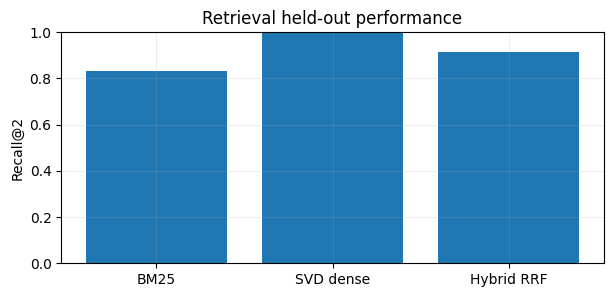

In [4]:
# Tune only on validation paraphrases; evaluate on untouched questions.
val=qdf.iloc[::2].reset_index(drop=True);test=qdf.iloc[1::2].reset_index(drop=True)
def recall_at_k(query_df,scorer,k):
 correct=[]
 for row in query_df.itertuples():correct.append(row.target_id in np.argsort(-scorer(row.query))[:k])
 return np.mean(correct)
configs=[]
for k1 in [.5,1.5,2.3]:
 for k in [5,20,60]:configs.append((k1,k,recall_at_k(val,lambda q:rrf(q,k1,k),2)))
bk1,brrf,_=max(configs,key=lambda a:a[2]);print('Validation search:',configs,'selected:',(bk1,brrf))
metrics={'BM25':recall_at_k(test,bm25,2),'SVD dense':recall_at_k(test,dense,2),'Hybrid RRF':recall_at_k(test,lambda q:rrf(q,bk1,brrf),2)}
print('Unseen paraphrase Recall@2:',metrics)
fig,ax=plt.subplots(figsize=(7,3));ax.bar(list(metrics),list(metrics.values()));ax.set(ylim=(0,1),ylabel='Recall@2',title='Retrieval held-out performance');plt.show()

## 4. Grounded answering and citations

A real LLM can be swapped in via the generator interface below. **The default offline answerer is extractive, NOT an LLM.** That distinction matters: retrieval evaluation is reproducible locally, while generative factuality requires a separate model and evaluation.

In [5]:
# Return policy-ID evidence and flag limitations of extractive answering.
def retrieve(query,k=2):
 scores=rrf(query,bk1,brrf);return docs.iloc[np.argsort(-scores)[:k]].copy()
def grounded_extract(query):
 matched=retrieve(query,2)
 if matched.empty:return {'answer':'I cannot locate supporting policy.','citations':[]}
 top=matched.iloc[0]
 return {'answer':top.body,'citations':[top.id],'policy_title':top.title}
for question in ['Can I make extra principal payments?','How do loan modifications work?']:
 response=grounded_extract(question);print('\nQ:',question,'\nA:',response)
coverage=np.mean([docs.iloc[int(row.target_id)].id in grounded_extract(row.query)['citations'] for row in test.itertuples()])
print('\nHeld-out top-one grounded evidence match:',round(coverage,3))


Q: Can I make extra principal payments? 
A: {'answer': 'A borrower may designate an extra payment for principal reduction subject to loan terms.', 'citations': ['P04'], 'policy_title': 'Extra principal'}

Q: How do loan modifications work? 
A: {'answer': 'Home equity is the difference between a property value and secured loan balances.', 'citations': ['P10'], 'policy_title': 'Home equity'}

Held-out top-one grounded evidence match: 0.833


## 5. Optional local LLM generation adapter (not executed by default)

To turn retrieval into a **generative** RAG system, replace the extractive step with a locally available Hugging Face instruction model. This deliberately avoids downloading model weights during tests and will only work when `transformers` and an appropriate checkpoint are installed locally. Output must still be checked for support.

In [6]:
# Return policy-ID evidence and flag limitations of extractive answering.
# Optional, NOT used in offline benchmark above. Real model availability varies by machine.
# from transformers import AutoTokenizer, AutoModelForCausalLM
# model_path = "/path/to/your/local-instruct-model"  # supply an existing local model directory
# tokenizer = AutoTokenizer.from_pretrained(model_path, local_files_only=True)
# llm = AutoModelForCausalLM.from_pretrained(model_path, local_files_only=True)
# evidence = retrieve("Can I change a mortgage payment?", k=2)
# prompt = ("Answer ONLY using the fictional policy excerpts below; cite IDs.\n"
#           + "\n".join(
#     f"[{r.id}] {r.body}" for r in evidence.itertuples())
# ... tokenize prompt, call llm.generate(...), decode and check citations.
print('Offline deliverable: fully working retrieval + extractive grounded answers. LLM generation is an explicit extension.')

Offline deliverable: fully working retrieval + extractive grounded answers. LLM generation is an explicit extension.


## What the results mean / interview discussion

This notebook demonstrates an auditable retrieval + grounding stack and separates offline **document match quality** from language generation quality. The text uses fictional rules and can never be used to answer real servicing-policy questions. The generation adapter is intentionally optional, so the benchmark runs without credentials, internet access or a GPU.

**Try explaining these without looking at the code:**

1. How do Recall@K, answer correctness and citation correctness differ?
2. What are retrieval leakage and document versioning failures?
3. How would you replace SVD with a trained dense bi-encoder and a cross-encoder reranker?

**Limitations and next step:** Evaluate on a suitably licensed real-world dataset or stronger simulation with domain shift, logging bias and realistic selection. Never treat synthetic performance as production evidence.

## What this project demonstrates, and what it does not

**Scope:** The executable path is a **retrieval + extractive evidence assistant**, not a benchmark of a deployed generative LLM. The notebook provides an optional local-model integration hook but no model weights. **Next:** add an actual instruction LLM, citations verification, abstention thresholds, policy versioning, and adversarial outdated documents.

**Reproduce:** `Run All` in Jupyter; no private or uploaded data required. For real data, use leakage-safe train/validation/test partitions and respect each dataset license.

In [7]:
# Honest failure analysis: list held-out questions answered from the wrong policy.
failures=[]
for row in test.itertuples():
    answer=grounded_extract(row.query)
    expected_id=docs.iloc[int(row.target_id)].id
    if expected_id not in answer["citations"]:
        failures.append({"question": row.query,
                         "expected_policy": expected_id,
                         "retrieved_policy": answer["citations"][0]})
print("Unreliable evidence matches:", len(failures), "of", len(test))
print(pd.DataFrame(failures).head(10).to_string(index=False) if failures else "None")

Unreliable evidence matches: 2 of 12
                               question expected_policy retrieved_policy
        What is the missed payment fee?             P02              P01
Where can I escalate a servicing issue?             P12              P03


**Safety of demonstrations:** When retrieval finds a wrong policy, the extractive answer also becomes wrong. Do not treat a citation as evidence of correctness unless the citation is independently verified. Production assistants need abstention, current-policy checks and an evaluated generation layer.